In [6]:
# Langkah 1 - Ilustrasi Data Non-Linier

# Langkah 1a - Import Library
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [7]:
# Langkah 1b - Buat Kembali Fungsi Plotting
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

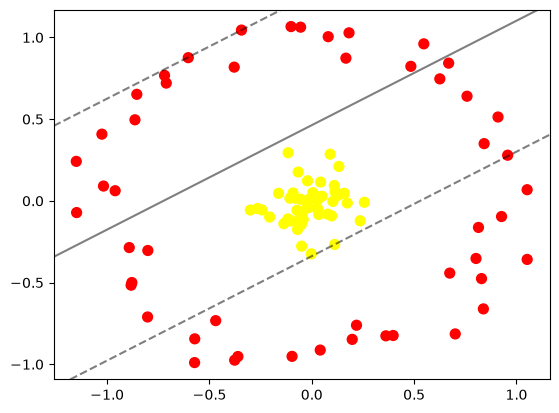

In [8]:
# Langkah 1c - Buat Data Dummy Non-Linier

# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [9]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    r = np.exp(-(X ** 2).sum(axis=1))
    ax = plt.figure().add_subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    plt.show()

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 0.08028985,  1.00446477],
       [-0.34339488,  1.0448667 ],
       [ 0.23658957, -0.12201235],
       [-0.3608212 , -0.95252324],
       [-0.02461522, -0.04424684],
       [-0.26479517, -0.04688857],
       [ 0.11430152,  0.06073719],
       [ 0.84206852,  0.35007272],
       [ 0.95702228,  0.27924426],
       [ 0.92712714, -0.09608462],
       [ 0.00517946,  0.04997099],
       [-0.46931848, -0.732959  ],
       [-0.80208486, -0.71061631],
       [-1.1488067 , -0.07175712],
       [-0.05668298, -0.10806091],
       [ 0.13057213,  0.03640804],
       [ 0.54733632,  0.96059607],
       [ 0.01196204,  0.03724105],
       [-0.04734342, -0.08327197],
       [-0.01599543,  0.00800284],
       [ 0.48407769,  0.8230309 ],
       [-0.10667544,  0.0164131 ],
       [ 0.25684995, -0.00879945],
       [ 0.67409705, -0.44212038],
       [-0.0663733 ,  0.17653885],
       [-0.57169882, -0.84427161],
       [ 1.05211144,  0.06810791],
       [

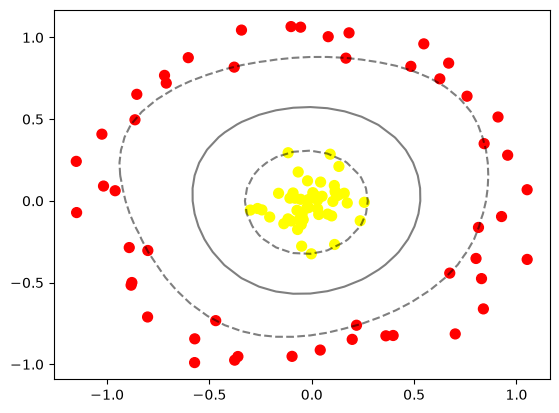

In [10]:
# Langkah 2 - Fitting Model

clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')